# Samadhi Model - MNIST Denoising Demo (Explained)

このノートブックでは、Samadhiモデルを使用して「ノイズ除去オートエンコーダ」のようなタスクを実行します。

**タスクの目的:**
ノイズが乗った手書き数字画像（MNIST）を入力し、Samadhiモデルの「概念探索（Vitakka）」と「状態純化（Vicara）」のプロセスを経て、きれいな画像に復元します。

**Samadhiモデルの特徴:**
単なるノイズ除去ではなく、モデルは入力画像が「どの数字（概念）に近いか」を能動的に探索し、その概念状態へと内部状態を収束させることで画像を再構成します。

## 🧘 Samadhiモデルの主要コンポーネントと設定

このデモで使用されているSamadhiモデルの主要なコンポーネントとその設定は以下の通りです。これらは `CONFIG_DICT` および `src/presets/vision.py` 内の `create_conv_samadhi` 関数に基づいて構成されています。

---

### Adapter (`CnnAdapter`)

* **役割**: 入力画像（32x32ピクセル、1チャンネル）を潜在空間の表現（次元数64）に変換します。
* **タイプ**: `cnn` (**畳み込みニューラルネットワーク**)
* **主な設定**:
    ```json
    "adapter": {
        "type": "cnn",
        "channels": 1,         # グレースケール画像
        "img_size": 32         # 処理のために28x28を32x32にリサイズ
    }
    ```

---

### Decoder (`CnnDecoder`)

* **役割**: 潜在空間の表現（次元数64）から再構成された画像（32x32ピクセル、1チャンネル）を生成します。
* **タイプ**: `cnn` (**畳み込みニューラルネットワーク**)
* **主な設定**:
    ```json
    "decoder": {
        "type": "cnn",
        "channels": 1,
        "img_size": 32
    }
    ```

---

### Objective (`SupervisedRegressionObjective`)

* **役割**: モデルの学習目標（**損失関数**）を定義します。再構成誤差、安定性、エントロピー、ロードバランスを考慮した損失を計算します。
* **タイプ**: `SupervisedRegressionObjective` クラスを直接使用。
* **主な設定**:
    ```json
    "objective": {
        "stability_coeff": 0.01, # 潜在状態の安定性に対する重み
        "entropy_coeff": 0.05,   # プローブ選択のエントロピーに対する重み
        "balance_coeff": 0.9,    # プローブの利用頻度の均一性に対する重み
    }
    ```

---

### Vitakka (`StandardVitakka`)

* **役割**: 入力された潜在状態から、最も関連性の高い「**概念（Probe）**」を探索し、初期状態 `s0` を生成します。
* **タイプ**: `standard` (SamadhiBuilderのデフォルト)
* **主な設定**:
    ```json
    "vitakka": {
        "n_probes": 10,              # 0-9の数字に対応する10個のプローブ
        "gate_threshold": -1,        # デモ用にゲートは常にオープン
        "mix_alpha": 0.2,            # 入力とプローブの混合比率
        "softmax_temp": 0.2,         # 確率分布のシャープネス調整
        "training_attention_mode": "soft", # 学習時は微分可能なソフトアテンション
        "prediction_attention_mode": "hard", # 推論時はハードアテンション
    }
    ```

---

### Vicara (`StandardVicara`)

* **役割**: Vitakkaで探索された初期状態 `s0` を、指定されたステップ数だけ繰り返し**純化（Refine）**し、最終的な収束状態 `s_final` を導出します。
* **タイプ**: `standard` (SamadhiBuilderのデフォルト)
* **主な設定**:
    ```json
    "vicara": {
        "refine_steps": 5,           # 状態純化の繰り返しステップ数
        "refiner_type": "mlp",       # 内部のRefinerネットワークのタイプ
        "inertia": 0.7               # 状態更新の慣性（前回の状態の影響度）
    }
    ```

---

### Refiners (`MlpRefiner`)

* **役割**: Vicaraの内部で使用されるネットワークで、潜在状態を**再帰的に洗練**させる役割を担います。
* **タイプ**: `mlp` (**多層パーセプトロン**)
* **主な設定**: SamadhiConfigのグローバルな `dim` (**64**) が内部的に伝搬され、Refinerの隠れ層の次元などに影響します。

## 1. ライブラリのインポート

必要なライブラリと、Samadhiフレームワークのコンポーネントを読み込みます。

In [8]:
import torch
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from src.presets.vision import create_conv_samadhi
from src.configs.main import SamadhiConfig
from src.train import SamadhiTrainer
from src.train.objectives.supervised_regression import SupervisedRegressionObjective

# デバイスの設定
if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print(f"Using device: {device}")

Using device: mps


## 2. モデル設定 (Configuration)

モデルの挙動を定義します。

*   **Img Size 32:** CNNの構造上、28x28のMNIST画像を32x32にリサイズして処理します。
*   **10 Probes:** 0〜9の数字に対応する10個の「概念の受け皿」を用意します。
*   **Refine Steps 5:** 内部で純化ループを5回回して、状態を安定させます。

In [9]:
CONFIG_DICT = {
    "dim": 64,  # Latent Dimension (潜在空間の次元数)
    "seed": 42,
    "labels": [str(i) for i in range(10)],  # ログ用ラベル

    # Adapter (CNN): 画像から潜在特徴を抽出
    "adapter": {
        "type": "cnn",
        "channels": 1,
        "img_size": 32  # 32x32にリサイズ
    },

    # Decoder (CNN): 潜在特徴から画像を再構成
    "decoder": {
        "type": "cnn",
        "channels": 1,
        "img_size": 32
    },

    # Vitakka (探索モジュール): 最適な概念(Probe)を探す
    "vitakka": {
        "n_probes": 10, # 0-9の10個の概念
        "gate_threshold": -1, # デモ用にゲートは常にオープン
        "mix_alpha": 0.2,
        "softmax_temp": 0.2,
        "training_attention_mode": "soft", # 学習時は微分可能にするためSoft Attention
        "prediction_attention_mode": "hard", # 推論時は1つの概念を選ぶHard Attention
    },

    # Vicara (純化モジュール): 状態を繰り返し洗練させる
    "vicara": {
        "refine_steps": 5, # 5回の思考ループ
        "refiner_type": "mlp",
        "inertia": 0.7
    },

    # Objective (学習目標)
    "objective": {
        "stability_coeff": 0.01, # 状態変化を小さくする（安定化）
        "entropy_coeff": 0.05,   # 曖昧さを減らす
        "balance_coeff": 0.9,    # 特定のProbeばかり使われるのを防ぐ
    }
}

## 3. データセットとノイズ注入

MNISTデータセットを読み込み、ガウシアンノイズを加えて「汚れた入力」を作ります。
また、画像を32x32にリサイズする前処理もここで行います。

In [10]:
def mnist_noise_injector(clean_img_tensor):
    """
    画像テンソルにガウシアンノイズを加える関数
    """
    noise = torch.randn_like(clean_img_tensor) * 0.7
    noisy_img = clean_img_tensor + noise
    return noisy_img

class MNISTPairDataset(Dataset):
    """
    (ノイズ画像, きれいな画像) のペアを提供するデータセット
    """

    def __init__(self, mnist_dataset, noise_fn):
        self.mnist_dataset = mnist_dataset
        self.noise_fn = noise_fn

    def __len__(self):
        return len(self.mnist_dataset)

    def __getitem__(self, idx):
        clean_img, label = self.mnist_dataset[idx]
        # clean_img は (1, 32, 32) のテンソル
        noisy_img = self.noise_fn(clean_img)

        # Trainerへの返り値
        # x: 入力, y: 目標(正解), class_label: 評価用ラベル
        return {
            "x": noisy_img,
            "y": clean_img,
            "class_label": torch.tensor(label, dtype=torch.long)
        }

## 4. 可視化関数

学習結果を確認するための関数です。

*   **`visualize_inference`**: ノイズ画像、復元画像、正解画像を並べて表示します。
*   **`visualize_probes`**: モデルが学習した「概念（Probe）」自体を画像として可視化します。「0」のProbeは本当に「0」の形をしているでしょうか？

In [11]:
def visualize_inference(trainer, dataloader, num_samples=5):
    """
    推論結果の可視化
    """
    device = trainer.args.device
    model = trainer.model
    model.eval()

    print("\n[Visualization] Running inference...")

    # バッチを取得
    batch = next(iter(dataloader))
    x_noisy = batch["x"][:num_samples].to(device)
    y_clean = batch["y"][:num_samples].to(device)
    labels = batch["class_label"][:num_samples]

    # 推論実行 (Samadhi Step)
    with torch.no_grad():
        output, s_final, meta = model(x_noisy, run_vitakka=True, run_vicara=True)

    # CPUへ移動
    x_noisy = x_noisy.cpu()
    y_clean = y_clean.cpu()
    output = output.cpu()

    # プロット
    fig, axes = plt.subplots(3, num_samples, figsize=(num_samples * 2, 6))

    rows = ["Input (Noisy)", "Output (Samadhi)", "Ground Truth"]

    for i in range(num_samples):
        # Input
        ax = axes[0, i]
        ax.imshow(x_noisy[i].squeeze(), cmap="gray")
        ax.set_title(f"Label: {labels[i].item()}")
        ax.axis("off")
        if i == 0: ax.set_ylabel("Input", fontweight='bold')

        # Output
        ax = axes[1, i]
        ax.imshow(output[i].squeeze(), cmap="gray")
        if i == 0: ax.set_ylabel("Reconstruction", fontweight='bold')
        ax.axis("off")

        # GT
        ax = axes[2, i]
        ax.imshow(y_clean[i].squeeze(), cmap="gray")
        if i == 0: ax.set_ylabel("Original", fontweight='bold')
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # 勝者Probeの表示
    if "winner_id" in meta:
        winners = meta["winner_id"]
        print("\n[Probe Winners for these samples]")
        for i in range(num_samples):
            print(f"Sample {i} (True: {labels[i].item()}) -> Winner Probe: {winners[i].item()}")


def visualize_probes(model, decoder, num_probes=10):
    """
    学習された概念(Probe)の可視化
    潜在空間にあるProbeをデコーダーに通して画像化します。
    """
    print("\n[Visualization] Visualizing Probes...")

    probes = model.vitakka.probes.data[:num_probes] # (N, Dim)

    model.eval()
    with torch.no_grad():
        decoded_probes = decoder(probes) # (N, C, H, W)

    decoded_probes = decoded_probes.cpu()

    fig, axes = plt.subplots(1, num_probes, figsize=(num_probes * 1.5, 2))
    for i in range(num_probes):
        if i >= len(decoded_probes): break
        ax = axes[i]
        ax.imshow(decoded_probes[i].squeeze(), cmap="gray")
        ax.set_title(f"Probe {i}")
        ax.axis("off")

    plt.suptitle("Learned Concept Probes (Latent Attractors)")
    plt.tight_layout()
    plt.show()

## 5. 実行: 準備とProbe初期化

モデルを作成し、学習のスタートダッシュを決めるために「Probeの初期化」を行います。
これは、0〜9の各数字の代表的な画像を1枚ずつ選び、それを初期の概念として覚え込ませる処理です。

Creating ConvSamadhi Model...
Loading MNIST Data...
Initializing probes with Representative Samples...
Probes initialized in Latent Space.

[Visualization] Visualizing Probes...


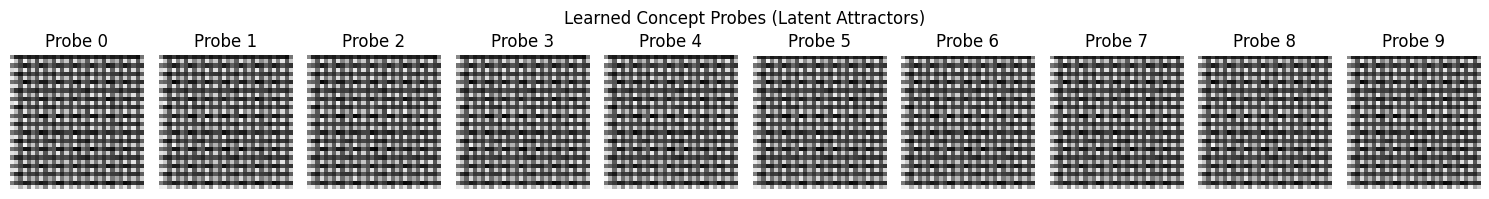

In [12]:
# 1. Config
config = SamadhiConfig.from_dict(CONFIG_DICT)

# 2. Model Creation
print("Creating ConvSamadhi Model...")
model = create_conv_samadhi(config)
model.to(device)

# 3. Data Preparation
print("Loading MNIST Data...")
transform = transforms.Compose([
    transforms.Resize((32, 32)), # 32x32にリサイズ
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset_raw = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_dataset_raw = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_dataset = MNISTPairDataset(train_dataset_raw, mnist_noise_injector)
test_dataset = MNISTPairDataset(test_dataset_raw, mnist_noise_injector)

# ---------------------------------------------------------
# Probe Initialization (Latent Space)
# ---------------------------------------------------------
print("Initializing probes with Representative Samples...")
representative_images = [None] * config.vitakka.n_probes
found_labels = [False] * config.vitakka.n_probes

# Iterate to find one image per digit
temp_loader = DataLoader(train_dataset_raw, batch_size=1, shuffle=True)
for img, label in temp_loader:
    lbl = label.item()
    if lbl < config.vitakka.n_probes and not found_labels[lbl]:
        representative_images[lbl] = img
        found_labels[lbl] = True
    if all(found_labels):
        break

# Stack images: (N, C, H, W)
rep_batch = torch.cat(representative_images, dim=0).to(device)

# Pass through Adapter to get Latent Vectors
model.eval()
with torch.no_grad():
    latent_probes = model.adapter(rep_batch) # (N, Dim)

# Assign to Probes
model.vitakka.probes.data = latent_probes
print("Probes initialized in Latent Space.")

# 初期状態のProbeを表示してみる
visualize_probes(model, model.decoder)

## 6. 学習開始 (Training)

Trainerを設定して学習を開始します。デモ用なのでEpoch数は少なめ（2回）に設定しています。

In [13]:
# 4. Trainer Setup
# Define Objective
objective = SupervisedRegressionObjective(config, device=device)

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./tmp_trainer",
    num_train_epochs=2, # デモ用に短く設定
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    logging_steps=50,
    remove_unused_columns=False, # カスタムデータセットのために必須
    label_names=["y"], # yをターゲットとして認識させる
    use_mps_device=(device == "mps"),
    report_to="none"
)

trainer = SamadhiTrainer(
    model=model,
    args=training_args,
    objective=objective,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    optimizers=(optimizer, None)
)

# 5. Training
print("\nStarting Training...")
trainer.train()

/Users/ryota/git_project/mine/samadhi_model/.venv/lib/python3.14/site-packages/transformers/training_args.py:2301: UserWarning: `use_mps_device` is deprecated and will be removed in version 5.0 of 🤗 Transformers. `mps` device will be used by default if available similar to the way `cuda` device is used.Therefore, no action from user is required. 
  warnings.warn(
/Users/ryota/git_project/mine/samadhi_model/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)



Starting Training...


Step,Training Loss
50,0.341500
100,0.212900
150,0.177100
200,0.161600
250,0.144000
300,0.132700
350,0.123400
400,0.115800
450,0.110800
500,0.106600


/Users/ryota/git_project/mine/samadhi_model/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


TrainOutput(global_step=1876, training_loss=0.09823134477967138, metrics={'train_runtime': 80.4923, 'train_samples_per_second': 1490.825, 'train_steps_per_second': 23.307, 'total_flos': 0.0, 'train_loss': 0.09823134477967138, 'epoch': 2.0})

## 7. 結果確認

学習後のモデルで推論を行い、どれくらいきれいにノイズが除去されたかを確認します。
また、学習によって洗練された「概念Probe」も可視化します。


[Visualization] Running inference...


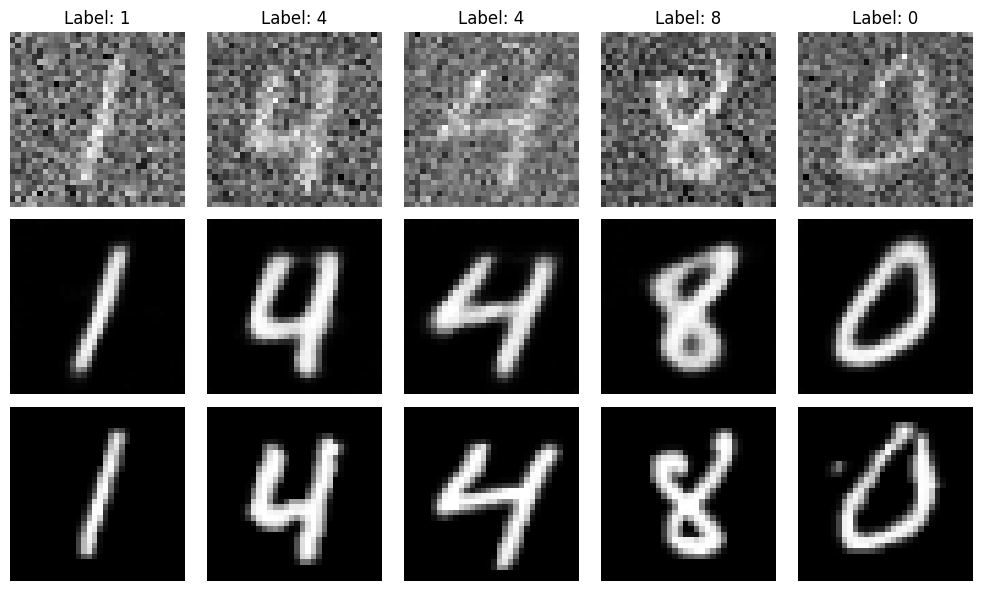


[Probe Winners for these samples]
Sample 0 (True: 1) -> Winner Probe: 8
Sample 1 (True: 4) -> Winner Probe: 4
Sample 2 (True: 4) -> Winner Probe: 4
Sample 3 (True: 8) -> Winner Probe: 9
Sample 4 (True: 0) -> Winner Probe: 6

[Visualization] Visualizing Probes...


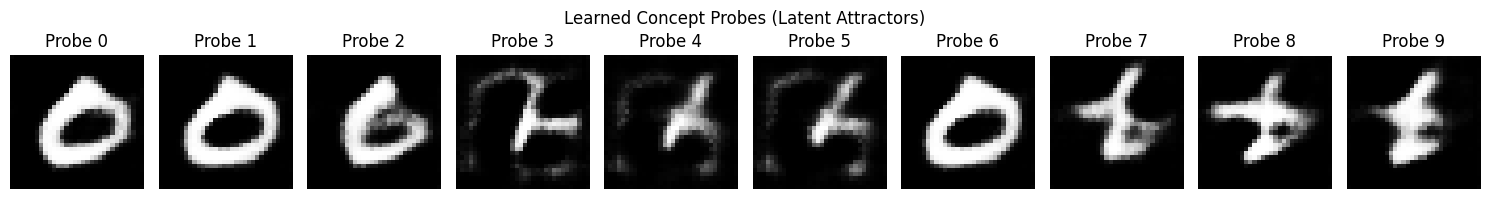

In [7]:
# 6. Evaluation / Visualization
test_loader = DataLoader(test_dataset, batch_size=10, shuffle=True)
visualize_inference(trainer, test_loader)
visualize_probes(model, model.decoder)